# Lab Day 10 — Qwen3-VL-4B: triển khai E0–E4
Chạy các cell **theo thứ tự** trên Colab L4. Mã của người làm nằm trong `vlm_lab/`;
giữ nguyên `scripts/` và `tests/`. Xem `COLAB.md` để biết cách tiếp tục khi mất session.
Đầu ra và số liệu chỉ được tạo từ những lần chạy thật. E5 là bonus: đã có reward + test,
chưa tích hợp vòng GRPO. Bạn cần đọc hiểu mã, kiểm chứng và tự viết 10 câu trong REPORT.md.

## 0. Môi trường (Colab L4)
Runtime → Change runtime type → **L4 GPU**. Sửa `REPO_URL` thành repo của bạn chứa mã này.
Nếu dùng ZIP, giải nén repo vào `/content/road-vlm` và đặt `REPO_URL = ""`.
Google Drive giữ checkpoint và predictions; dữ liệu và model cache nằm trên ổ Colab cho nhanh.

In [14]:
from google.colab import drive
drive.mount('/content/drive')
import os, sys, subprocess, shutil, json
from pathlib import Path

def run_cmd(*args, check=True):
    command = [str(a) for a in args]
    child_env = os.environ.copy()
    child_env["PYTHONUNBUFFERED"] = "1"
    child_env["PYTHONIOENCODING"] = "utf-8"
    print("Running:", " ".join(command), flush=True)
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, encoding="utf-8", errors="replace", bufsize=1,
                          env=child_env) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
    if check and returncode:
        raise subprocess.CalledProcessError(returncode, command)
    return subprocess.CompletedProcess(command, returncode)

REPO_URL = "https://github.com/Munfond/K4-Track-4-Day10-VisionLanguageModel.git"
REPO_DIR = Path("/content/road-vlm")
ARTIFACT_DIR = Path("/content/drive/MyDrive/road-vlm-day10")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
if not REPO_DIR.exists():
    assert REPO_URL, "Giải nén ZIP vào /content/road-vlm trước."
    run_cmd("git", "clone", REPO_URL, str(REPO_DIR))
os.chdir(REPO_DIR)
assert (REPO_DIR / "vlm_lab/runner.py").exists(), "Repo Colab chưa có mã mới: push mã hoặc upload ZIP."
# Khôi phục bằng chứng đã lưu nếu đây là session mới.
if (ARTIFACT_DIR / "report").exists():
    shutil.copytree(ARTIFACT_DIR / "report", REPO_DIR / "report", dirs_exist_ok=True)
# Predictions ghi trực tiếp vào Drive để có thể tiếp tục batch còn thiếu.
(ARTIFACT_DIR / "work").mkdir(exist_ok=True)
work = REPO_DIR / "work"
if not work.exists():
    work.symlink_to(ARTIFACT_DIR / "work", target_is_directory=True)
else:
    assert work.is_symlink() and work.resolve() == (ARTIFACT_DIR / "work").resolve(), "work đã tồn tại; chọn checkout Colab mới."
CHECKPOINT_ROOT = ARTIFACT_DIR / "checkpoints"
CHECKPOINT_ROOT.mkdir(exist_ok=True)

def lab(*args):
    run_cmd(sys.executable, "-m", "vlm_lab.runner", *args)

def backup_reports():
    shutil.copytree(REPO_DIR / "report", ARTIFACT_DIR / "report", dirs_exist_ok=True)

run_cmd("nvidia-smi", "-L")
run_cmd(sys.executable, "-m", "pip", "install", "-r", "requirements-colab.txt", "pytest")
# Colab có thể có xung đột từ các package không dùng trong lab; vẫn in để kiểm tra.
run_cmd(sys.executable, "-m", "pip", "check", check=False)
run_cmd(sys.executable, "-c", "import torch, torchvision, transformers, peft, bitsandbytes; "
        "assert torch.cuda.is_available(); print('GPU and lab imports: OK')")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running: nvidia-smi -L
GPU 0: NVIDIA L4 (UUID: GPU-7ec20e68-0405-71c9-60e8-3119f1e759a4)
Running: /usr/bin/python3 -m pip install -r requirements-colab.txt pytest
Running: /usr/bin/python3 -m pip check
ipython 7.34.0 requires jedi, which is not installed.
Running: /usr/bin/python3 -c import torch, torchvision, transformers, peft, bitsandbytes; assert torch.cuda.is_available(); print('GPU and lab imports: OK')
GPU and lab imports: OK


CompletedProcess(args=['/usr/bin/python3', '-c', "import torch, torchvision, transformers, peft, bitsandbytes; assert torch.cuda.is_available(); print('GPU and lab imports: OK')"], returncode=0)

Các lệnh GPU chạy bằng subprocess nên không cần import torch/model vào kernel notebook.
Nếu cài đặt báo xung đột torch/torchvision, xem COLAB.md trước khi chạy tiếp.

In [15]:
run_cmd(sys.executable, "-m", "pytest", "-q")
run_cmd(sys.executable, "-m", "pytest", "-q", "student_checks")

Running: /usr/bin/python3 -m pytest -q
...........................s.........................................    [100%]
68 passed, 1 skipped in 0.28s
Running: /usr/bin/python3 -m pytest -q student_checks
......................                                                   [100%]
22 passed in 9.12s


CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q', 'student_checks'], returncode=0)

## 1. Dữ liệu: tải và chia split
Chọn `DATA_MODE`: `kaggle`, `zip`, hoặc `source`. Kaggle: tạo Colab Secrets
`KAGGLE_USERNAME`, `KAGGLE_KEY`, bật quyền truy cập cho notebook. Không ghi khóa vào cell.

In [16]:
DATA_MODE = "kaggle"
DATA_PATH = "/content/drive/MyDrive/dataset.zip"  # chỉ dùng cho zip/source
DATA_CACHE = "/content/dataset_cache"  # tải/giải nén trên ổ Colab, không dùng work/ trên Drive
if DATA_MODE == "kaggle":
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    run_cmd(sys.executable, "scripts/prepare_data.py", "--kaggle", "--work", DATA_CACHE)
elif DATA_MODE in ("zip", "source"):
    run_cmd(sys.executable, "scripts/prepare_data.py", "--"+DATA_MODE, DATA_PATH, "--work", DATA_CACHE)
else:
    raise ValueError(DATA_MODE)

Running: /usr/bin/python3 scripts/prepare_data.py --kaggle --work /content/dataset_cache
Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT

  0%|          | 0.00/185M [00:00<?, ?B/s]
  1%|          | 1.00M/185M [00:01<03:12, 1.00MB/s]
  1%|          | 2.00M/185M [00:01<01:38, 1.95MB/s]
  2%|▏         | 3.00M/185M [00:01<01:01, 3.10MB/s]
  3%|▎         | 5.00M/185M [00:01<00:33, 5.71MB/s]
  4%|▍         | 8.00M/185M [00:01<00:18, 9.88MB/s]
  6%|▌         | 11.0M/185M [00:01<00:13, 13.1MB/s]
  7%|▋         | 13.0M/185M [00:01<00:12, 14.6MB/s]
  9%|▊         | 16.0M/185M [00:01<00:10, 17.2MB/s]
 10%|█         | 19.0M/185M [00:02<00:09, 19.3MB/s]
 12%|█▏        | 22.0M/185M [00:02<00:08, 20.2MB/s]
 14%|█▎        | 25.0M/185M [00:02<00:08, 20.8MB/s]
 15%|█▌        | 28.0M/185M [00:02<00:07, 20.9MB/s]
 17%|█▋        | 31.0M/185M [00:02<00:07, 21.6MB/s]
 18%|█▊        | 34.0M/185M [00:02<00:07, 22.3MB/s]
 20%|█▉       

## 2. Nhãn: YOLO → JSON thang 0–1000
Cell này kiểm tra split, chuyển đổi qua lại tọa độ, prefix chat template, mask loss,
220 token ảnh và collator. Xem 6 ảnh: xanh là nhãn gốc, đỏ là nhãn đã chuyển đổi.

Running: /usr/bin/python3 -m vlm_lab.runner inspect
{
  "dataset_version": "d10-21e4070301",
  "counts": {
    "train": {
      "images": 1422,
      "boxes": {
        "pothole": 1074,
        "crack": 1750,
        "manhole": 691
      }
    },
    "val": {
      "images": 276,
      "boxes": {
        "pothole": 66,
        "crack": 470,
        "manhole": 103
      }
    },
    "test": {
      "images": 311,
      "boxes": {
        "pothole": 121,
        "crack": 299,
        "manhole": 163
      }
    }
  },
  "target_policy": "Skip zero/nonpositive visible area; expand positive boxes collapsed by rounding to one unit.",
  "scoring_policy": "Original splits and score.py unchanged; skipped GT boxes remain in official evaluation.",
  "annotation_quality": {
    "train": {
      "skipped_target_boxes": 1,
      "skipped_by_class": {
        "crack": 1
      },
      "skipped_examples": [
        {
          "image_id": "vlcsnap-00058",
          "object_index": 1,
          "label"

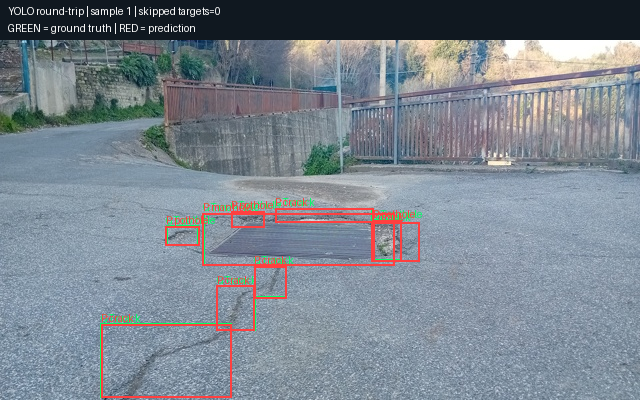

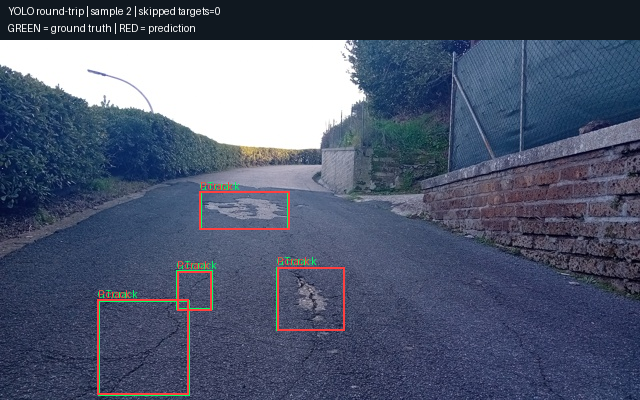

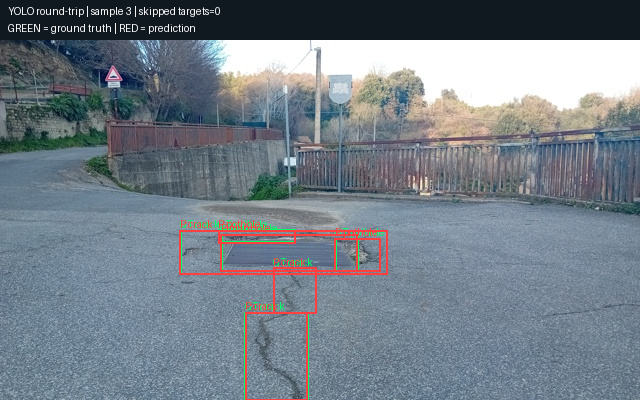

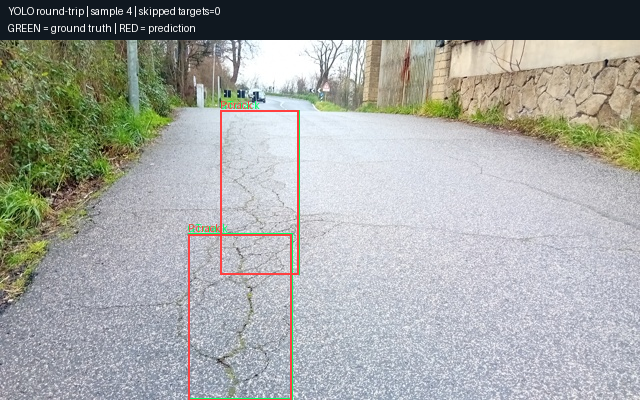

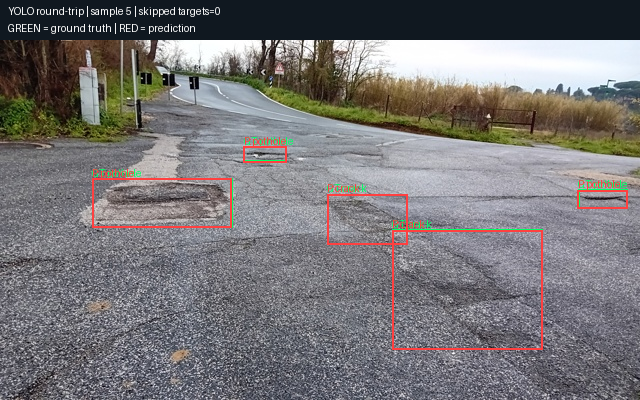

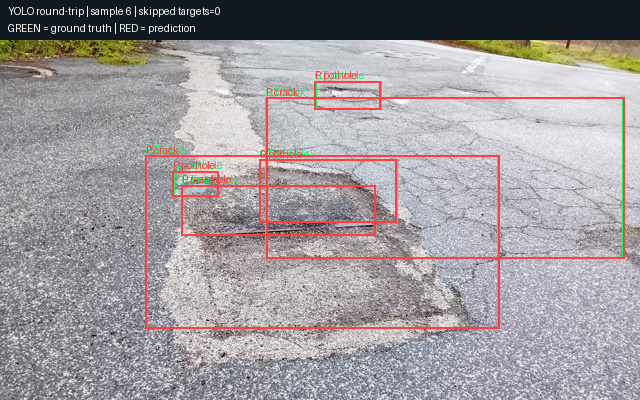

In [17]:
lab("inspect")
from IPython.display import display, Image as DisplayImage, Markdown
for image in sorted(Path("report/figures/data").glob("*.png")):
    display(DisplayImage(filename=str(image)))
backup_reports()

## 3. E0: zero-shot
Chạy thử 8 ảnh val, đọc output thô; sau đó chạy đủ val và test.
Không chỉnh prompt/hyperparameter dựa trên test. Predictions có manifest để tránh trộn các lần chạy.

In [18]:
INFER_BATCH = 4  # Nếu OOM, đổi thành 1; không thay đổi dự đoán greedy theo thiết kế.
lab("infer", "--split", "val", "--limit", 8, "--batch-size", INFER_BATCH, "--out", "work/e0_smoke.jsonl")
from scripts.labcommon import read_jsonl
for row in read_jsonl("work/e0_smoke.jsonl")[:5]:
    print(row["image_id"], row["raw"], "\n")

Running: /usr/bin/python3 -m vlm_lab.runner infer --split val --limit 8 --batch-size 4 --out work/e0_smoke.jsonl
All predictions already saved; skipping generation.
vlcsnap-2025-02-18-18h30m17s408 [{"label": "crack", "bbox_2d": [0, 370, 1000, 700], "confidence": 0.7}, {"label": "crack", "bbox_2d": [0, 370, 1000, 700], "confidence": 0.7}, {"label": "crack", "bbox_2d": [0, 370, 1000, 700], "confidence": 0.7}, {"label": "crack", "bbox_2d": [0, 370, 1000, 700], "confidence": 0.7}, {"label": "manhole", "bbox_2d": [350, 286, 367, 300], "confidence": 0.7}, {"label": "manhole", "bbox_2d": [350, 286, 367, 300], "confidence": 0.7}, {"label": "manhole", "bbox_2d": 

vlcsnap-2025-02-18-18h30m20s293 [{"label": "crack", "bbox_2d": [0, 500, 1000, 999], "confidence": 0.7}, {"label": "crack", "bbox_2d": [0, 375, 1000, 999], "confidence": 0.7}, {"label": "crack", "bbox_2d": [0, 330, 1000, 999], "confidence": 0.7}, {"label": "crack", "bbox_2d": [0, 290, 1000, 999], "confidence": 0.7}, {"label": "crack", 

In [19]:
Path("work/validation").mkdir(parents=True, exist_ok=True)
lab("infer", "--split", "val", "--batch-size", INFER_BATCH, "--out", "work/e0_val.jsonl")
lab("score", "--pred", "work/e0_val.jsonl", "--name", "E0-val", "--out", "work/validation/e0.json")
lab("infer", "--split", "test", "--batch-size", INFER_BATCH, "--out", "work/e0.jsonl")
lab("score", "--pred", "work/e0.jsonl", "--name", "E0", "--out", "report/evidence/e0.json")
backup_reports()

Running: /usr/bin/python3 -m vlm_lab.runner infer --split val --batch-size 4 --out work/e0_val.jsonl
All predictions already saved; skipping generation.
Running: /usr/bin/python3 -m vlm_lab.runner score --pred work/e0_val.jsonl --name E0-val --out work/validation/e0.json
E0-val [val] n=276 valid=0.641 P=0.044 R=0.028 F1=0.034 CI95=0.021-0.051 meanIoU=0.587 FP/img=1.40
   pothole  P=0.028 R=0.015 F1=0.020
   crack    P=0.025 R=0.011 F1=0.015
   manhole  P=0.071 R=0.117 F1=0.088
Running: /usr/bin/python3 -m vlm_lab.runner infer --split test --batch-size 4 --out work/e0.jsonl
All predictions already saved; skipping generation.
Running: /usr/bin/python3 -m vlm_lab.runner score --pred work/e0.jsonl --name E0 --out report/evidence/e0.json
E0 [test] n=311 valid=0.518 P=0.079 R=0.050 F1=0.061 CI95=0.041-0.082 meanIoU=0.613 FP/img=1.09
   pothole  P=0.233 R=0.083 F1=0.122
   crack    P=0.012 R=0.007 F1=0.009
   manhole  P=0.108 R=0.104 F1=0.106


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss
Các hàm nằm trong `vlm_lab/modeling.py`: `encode_example`, `collate_examples`.
Chạy smoke test 2 bước E1 để kiểm tra forward/backward/save/load trước lần train thật.
Smoke test có thư mục riêng và không được nộp làm bằng chứng E1.

In [20]:
smoke_dir = CHECKPOINT_ROOT / "smoke_e1"
smoke_args = ["train", "--config", "configs/e1.yaml", "--run-dir", smoke_dir,
              "--max-steps", 2, "--save-every", 1]
if (smoke_dir / "latest.json").exists():
    smoke_args.append("--resume")
lab(*smoke_args)
lab("infer", "--checkpoint", smoke_dir, "--split", "val", "--limit", 8,
    "--batch-size", INFER_BATCH, "--out", "work/e1_smoke.jsonl")

Running: /usr/bin/python3 -m vlm_lab.runner train --config configs/e1.yaml --run-dir /content/drive/MyDrive/road-vlm-day10/checkpoints/smoke_e1 --max-steps 2 --save-every 1 --resume
Training already complete; proceed to inference.
Running: /usr/bin/python3 -m vlm_lab.runner infer --checkpoint /content/drive/MyDrive/road-vlm-day10/checkpoints/smoke_e1 --split val --limit 8 --batch-size 4 --out work/e1_smoke.jsonl
All predictions already saved; skipping generation.


## 5. Setup LoRA / đóng băng cho E1, E2, E3
E1: 252 module LLM. E2: cùng LoRA + projector fp32 (~109M). E3: 348 module LLM+ViT + projector.
`apply_setup` xác nhận module và lưu `modules.json`. Mọi tham số được học ở fp32 để GradScaler hoạt động.

In [21]:
stats = json.loads((smoke_dir / "modules.json").read_text())
print("E1 trainable params:", stats["trainable_params"])
print("Matched modules:", len(stats["matched_modules"]))
print("First targets:", stats["matched_modules"][:10])

E1 trainable params: 33030144
Matched modules: 252
First targets: ['model.language_model.layers.0.self_attn.q_proj', 'model.language_model.layers.0.self_attn.k_proj', 'model.language_model.layers.0.self_attn.v_proj', 'model.language_model.layers.0.self_attn.o_proj', 'model.language_model.layers.0.mlp.gate_proj', 'model.language_model.layers.0.mlp.up_proj', 'model.language_model.layers.0.mlp.down_proj', 'model.language_model.layers.1.self_attn.q_proj', 'model.language_model.layers.1.self_attn.k_proj', 'model.language_model.layers.1.self_attn.v_proj']


## 6. Vòng huấn luyện
Chạy E1 → E2 → E3, mỗi lần khởi tạo từ model gốc. Mặc định 300 bước như configs.
Checkpoint mỗi 100 bước (adapter, projector nếu có, optimizer, scaler, RNG).
Để xử lý OOM, đặt `TRAIN_OVERRIDES = ["--batch-size", 1, "--grad-accum", 8]`
**trước lần chạy đầu**, dùng cùng lựa chọn cho E1–E3 và E4 để so sánh công bằng.
Sau khi mất session: chạy lại các bước chuẩn bị rồi cell này với cùng cấu hình; run hoàn tất được bỏ qua.

In [28]:
TRAIN_OVERRIDES = []
# Có thể chạy từng setup bằng RUNS = ["e1"], rồi ["e2"], rồi ["e3"].
RUNS = ["e1", "e2", "e3"]
for key in RUNS:
    directory = CHECKPOINT_ROOT / key
    args = ["train", "--config", f"configs/{key}.yaml", "--run-dir", directory, *TRAIN_OVERRIDES]
    if (directory / "latest.json").exists():
        args.append("--resume")
    lab(*args)
    lab("infer", "--checkpoint", directory, "--split", "val", "--batch-size", INFER_BATCH,
        "--out", f"work/{key}_val.jsonl")
    lab("score", "--pred", f"work/{key}_val.jsonl", "--name", key.upper()+"-val",
        "--out", f"work/validation/{key}.json")
    print(json.loads((directory / "run.json").read_text()))

Running: /usr/bin/python3 -m vlm_lab.runner train --config configs/e1.yaml --run-dir /content/drive/MyDrive/road-vlm-day10/checkpoints/e1

Loading weights: 100%|██████████| 713/713 [00:04<00:00, 161.05it/s]
Quantization check: 252 LLM Linear4bit modules; ViT/projectors/lm_head floating point
{'trainable_params': 33030144, 'projector_params': 0}
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step=1/300 loss=1.2898 peak=5.50GB time=0.2min
step=10/300 loss=0.8002 peak=6.42GB time=0.9min
step=20/300 loss=0.7272 peak=6.42GB time=1.8min
step=30/300 loss=0.6577 peak=6.42GB time=2.7min
step=40/300 loss=0.6422 peak=6.42GB time=3.6min
step=50/300 loss=0.5822 peak=6.44GB time=4.6min
step=60/300 loss=0.6853 peak=6.55GB time=5.5min
step=70/300 loss=0.6370 peak=6.55GB time=6.4min
step=80/300 loss=0.6833 peak=6.55GB time=7.3min
step=90/300 loss=0.6105 peak=6.55GB time=8.2min
step=100/300 loss=0.6566 peak=6.55GB time=9.1min
Copying checkpoint st

## 7. Suy luận và chấm E1–E3
Chỉ chạy sau khi train hoàn tất và đã kiểm tra val. Chấm đủ 311 ảnh test cho mỗi setup.
Scorer lấy metadata trực tiếp từ run.json. Cell tạo bảng kết quả và 6 ảnh minh họa đúng/sai.

In [29]:
for key in RUNS:
    lab("infer", "--checkpoint", CHECKPOINT_ROOT / key, "--split", "test",
        "--batch-size", INFER_BATCH, "--out", f"work/{key}.jsonl")
    lab("score", "--pred", f"work/{key}.jsonl", "--name", key.upper(),
        "--out", f"report/evidence/{key}.json")
    lab("visualize", "--pred", f"work/{key}.jsonl", "--out", f"report/figures/{key}")
    backup_reports()
lab("summarize")
display(Markdown(Path("report/results.md").read_text()))

Running: /usr/bin/python3 -m vlm_lab.runner infer --checkpoint /content/drive/MyDrive/road-vlm-day10/checkpoints/e1 --split test --batch-size 4 --out work/e1.jsonl

Loading weights: 100%|██████████| 713/713 [00:04<00:00, 167.88it/s]
Quantization check: 252 LLM Linear4bit modules; ViT/projectors/lm_head floating point
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
Predictions 4/311
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
Predictions 8/311
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
Predictions 12/311
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
Predictions 16/311
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
Predictions 20/311
[transformers] Kwargs passed to `proce

# Results from score.py

Copy this table into REPORT.md and write your own analysis.

E0 minutes/VRAM refer to inference; trained setups refer to training. E0 training time is zero.

| Run | Trainable params | Peak VRAM GB | Minutes | F1 | CI95 | FP/image | pothole F1 | crack F1 | manhole F1 |
|---|---:|---:|---:|---:|---|---:|---:|---:|---:|
| E0 | 0 | 3.779364585876465 | 32.155419514883334 | 0.0610 | [0.0406, 0.0817] | 1.0900 | 0.1220 | 0.0086 | 0.1059 |
| E1 | 33030144 | 6.677389144897461 | 27.400791853599994 | 0.2617 | [0.2247, 0.3023] | 1.3505 | 0.1696 | 0.1967 | 0.5097 |
| E2 | 142135296 | 8.371910095214844 | 28.367548015500006 | 0.3495 | [0.3103, 0.3921] | 1.1318 | 0.2130 | 0.2839 | 0.6087 |
| E3 | 148426752 | 8.550133228302002 | 32.97329237305001 | 0.4400 | [0.4009, 0.4838] | 1.0096 | 0.3077 | 0.3799 | 0.6829 |


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)
Mặc định E4 là **data_size**: 10% vs 100% train, giữ các cấu hình khác của setup tốt nhất trên val.
Kết quả 100% được dùng lại từ run nền; chạy thêm 10%. Có thể đổi `E4_VARIABLE` thành `rank`
(4 vs 64) hoặc `coord_scale` (norm1000 vs pixel). Với pixel, prompt/nhãn/scorer tự đổi đồng bộ.
Không đổi lựa chọn E4 dựa trên điểm test. Với rank 64 trên E3, hãy kiểm tra VRAM L4 trong lần chạy thử.

In [30]:
import copy, yaml
E4_VARIABLE = "data_size"
keys = ["e1", "e2", "e3"]
val_scores = {k: json.loads(Path(f"work/validation/{k}.json").read_text())["micro"]["f1"] for k in keys}
BEST = max(keys, key=lambda k: val_scores[k])
base_run = json.loads((CHECKPOINT_ROOT / BEST / "run.json").read_text())
base_cfg = base_run["config"]
print("Base chosen on val:", BEST, val_scores)
values = {"rank": [4, 64], "data_size": [0.1, 1.0], "coord_scale": ["norm1000", "pixel"]}[E4_VARIABLE]
for value in values:
    cfg = copy.deepcopy(base_cfg)
    if E4_VARIABLE == "rank":
        cfg["lora"].update(r=value, alpha=2*value)
    elif E4_VARIABLE == "data_size":
        cfg["train_fraction"] = value
    else:
        cfg["coord"] = value
    key = f"e4_{E4_VARIABLE}_{value}"
    cfg_path = Path(f"work/{key}.yaml")
    cfg_path.write_text(yaml.safe_dump(cfg, sort_keys=False))
    reuse_base = cfg == base_cfg
    if reuse_base:
        directory = CHECKPOINT_ROOT / BEST
        pred_file = f"work/{BEST}.jsonl"
    else:
        directory = CHECKPOINT_ROOT / key
        args = ["train", "--config", cfg_path, "--run-dir", directory]
        if (directory / "latest.json").exists():
            args.append("--resume")
        lab(*args)
        lab("infer", "--checkpoint", directory, "--split", "val", "--batch-size", INFER_BATCH,
            "--out", f"work/{key}_val.jsonl")
        lab("score", "--pred", f"work/{key}_val.jsonl", "--name", key.upper()+"-val",
            "--out", f"work/validation/{key}.json")
        pred_file = f"work/{key}.jsonl"
        lab("infer", "--checkpoint", directory, "--split", "test", "--batch-size", INFER_BATCH, "--out", pred_file)
    lab("score", "--pred", pred_file, "--name", key.upper(), "--out", f"report/evidence/{key}.json")
    backup_reports()
lab("summarize")
backup_reports()
display(Markdown(Path("report/results.md").read_text()))

Base chosen on val: e3 {'e1': 0.21333333333333332, 'e2': 0.29947460595446584, 'e3': 0.3470031545741325}
Running: /usr/bin/python3 -m vlm_lab.runner train --config work/e4_data_size_0.1.yaml --run-dir /content/drive/MyDrive/road-vlm-day10/checkpoints/e4_data_size_0.1

Loading weights: 100%|██████████| 713/713 [00:04<00:00, 171.89it/s]
Quantization check: 252 LLM Linear4bit modules; ViT/projectors/lm_head floating point
{'trainable_params': 148426752, 'projector_params': 109105152}
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step=1/300 loss=1.4616 peak=6.51GB time=0.1min
Gradient overflow step=3; retry=1, scale=32768.0
step=10/300 loss=0.7656 peak=7.84GB time=1.2min
Gradient overflow step=14; retry=1, scale=16384.0
Gradient overflow step=14; retry=2, scale=8192.0
step=20/300 loss=0.6518 peak=7.95GB time=2.4min
step=30/300 loss=0.6659 peak=7.95GB time=3.5min
step=40/300 loss=0.5344 peak=7.95GB time=4.5min
step=50/300 loss=0.4936 

# Results from score.py

Copy this table into REPORT.md and write your own analysis.

E0 minutes/VRAM refer to inference; trained setups refer to training. E0 training time is zero.

| Run | Trainable params | Peak VRAM GB | Minutes | F1 | CI95 | FP/image | pothole F1 | crack F1 | manhole F1 |
|---|---:|---:|---:|---:|---|---:|---:|---:|---:|
| E0 | 0 | 3.779364585876465 | 32.155419514883334 | 0.0610 | [0.0406, 0.0817] | 1.0900 | 0.1220 | 0.0086 | 0.1059 |
| E1 | 33030144 | 6.677389144897461 | 27.400791853599994 | 0.2617 | [0.2247, 0.3023] | 1.3505 | 0.1696 | 0.1967 | 0.5097 |
| E2 | 142135296 | 8.371910095214844 | 28.367548015500006 | 0.3495 | [0.3103, 0.3921] | 1.1318 | 0.2130 | 0.2839 | 0.6087 |
| E3 | 148426752 | 8.550133228302002 | 32.97329237305001 | 0.4400 | [0.4009, 0.4838] | 1.0096 | 0.3077 | 0.3799 | 0.6829 |
| E4_DATA_SIZE_0.1 | 148426752 | 7.9500885009765625 | 32.31635250616667 | 0.2890 | [0.2564, 0.3236] | 1.7235 | 0.1469 | 0.2199 | 0.5931 |
| E4_DATA_SIZE_1.0 | 148426752 | 8.550133228302002 | 32.97329237305001 | 0.4400 | [0.4009, 0.4838] | 1.0096 | 0.3077 | 0.3799 | 0.6829 |


### E5 bonus: reward IoU
`vlm_lab/reward.py` có reward Python thuần và test (hoàn hảo, JSON hỏng, sai lớp, thừa box, rỗng).
Phần GRPO chưa được triển khai/chạy; không ghi nhận bonus GRPO nếu chỉ chạy reward test.

In [31]:
run_cmd(sys.executable, "-m", "pytest", "-q", "student_checks/test_reward.py")

Running: /usr/bin/python3 -m pytest -q student_checks/test_reward.py
..                                                                       [100%]
2 passed in 0.01s


CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-q', 'student_checks/test_reward.py'], returncode=0)

## 9. Báo cáo và xuất kết quả
Điền REPORT.md bằng số thật từ report/results.md, đọc ví dụ trong report/figures/*/index.md,
trả lời 10 câu bằng hiểu biết của bạn. Không thay template bằng câu trả lời giả để vượt checker.
Cell sau kiểm tra chấm lệch tọa độ cho Câu 3; kết quả nằm trong work, không thay evidence chuẩn.

In [32]:
# Diagnostic only: chấm cùng output norm1000 dưới giả định pixel sai.
run_cmd(sys.executable, "scripts/score.py", "--pred", "work/e1.jsonl", "--coord", "pixel",
        "--name", "E1-wrong-scale-diagnostic", "--out", "work/e1_wrong_scale.json")
correct = json.loads(Path("report/evidence/e1.json").read_text())["micro"]["f1"]
wrong = json.loads(Path("work/e1_wrong_scale.json").read_text())["micro"]["f1"]
print("F1 correct scale:", correct, "| F1 wrong scale:", wrong)

Running: /usr/bin/python3 scripts/score.py --pred work/e1.jsonl --coord pixel --name E1-wrong-scale-diagnostic --out work/e1_wrong_scale.json
E1-wrong-scale-diagnostic [test] n=311 valid=0.997 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.84
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000
F1 correct scale: 0.2616984402079723 | F1 wrong scale: 0.0


In [33]:
backup_reports()
# Chỉ đóng gói report/: không kèm data, secrets hoặc trọng số.
bundle = shutil.make_archive(str(ARTIFACT_DIR / "lab_results"), "zip", root_dir=REPO_DIR, base_dir="report")
print("Results ZIP:", bundle)
# FAIL lúc này có thể là REPORT còn trống hoặc repo chưa đủ commit. Xem từng mục, sửa thật rồi kiểm tra lại.
result = run_cmd(sys.executable, "scripts/check_submission.py", check=False)
print("Submission checker exit code:", result.returncode)

Results ZIP: /content/drive/MyDrive/road-vlm-day10/lab_results.zip
Running: /usr/bin/python3 scripts/check_submission.py
[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4 — 2 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] e3 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[FAIL] REPORT.md đã điền — còn chuỗi '<điền'
[PASS] git commits — 9/5
[PASS] git forbidden files

1 FAIL, 0 WARN
Submission checker exit code: 1


Tải `lab_results.zip` từ Drive, chép `report/` về repo local. Điền REPORT.md, commit theo các bước
(ít nhất 5 commit có ý nghĩa), push repo công khai, chạy lại checker trên repo local.
Để nộp notebook có output: File → Download → Download .ipynb và thay bản trong repo.
Không push checkpoint/adapter/projector hoặc predictions trong work/. Không cần chạy GRPO để hoàn thành phần bắt buộc.

## Ghi chú nghiệm thu hồ sơ cuối
Notebook giữ nguyên output thực nghiệm đã chạy. Dòng FAIL REPORT ở cell kiểm tra cuối là kết quả lúc REPORT còn template; hồ sơ sau đó đã hoàn thiện và kiểm tra riêng. Xem `REPORT.md`, `CHECKLIST.md`, `BAO_CAO_LOI_VA_LUU_Y.md` và `report/verification/submission_check.txt` (0 FAIL, 0 WARN).
Test gốc yêu cầu REPORT còn marker template mâu thuẫn với yêu cầu bài nộp; ngoại lệ này được ghi công khai và test/report cuối được kiểm tra riêng, không sửa scripts/tests của đề.